# 01 Preprocess: from SEC BDC filings to a dataset of newly originated private credit loans

**Question.** What credit spread over SOFR (in percentage points) should a deal team expect for a newly
originated US private credit loan, before the term sheet is signed?

**What this notebook does.** It downloads the SEC "Business Development Company (BDC) Data Sets", keeps the
schedule-of-investments line items (`soi.tsv`), identifies each BDC's newly added loans, builds the features that
are known at the cutoff, and writes two files:

- `data/processed/loans.csv`: main sample, BDCs whose filings state the industry of each borrower (core families);
- `data/processed/loans_all_bdc.csv`: same rules for all BDCs, industry may be missing (robustness check).

**What is fixed** (CLAUDE.md and `docs/lecturer_feedback_and_commitments.md`):
- Unit: one new loan = one borrower x one manager family x one quarter of first appearance.
  New = no BDC of the same family held the borrower before; loans whose reported acquisition date is before the
  quarter are dropped; borrowers seen earlier at an unaffiliated BDC are flagged.
- Target: spread over SOFR in percentage points.
- Cutoff: start of the quarter of first appearance. Market-level spread from quarter t-2 filings, checked with
  the SEC filing date. External market data: last value before the cutoff.
- Never features: interest rate, fair value, cost, PIK, floor (kept only as descriptive columns).
- No model fitting and no learned preprocessing here (that belongs in pipelines in notebook 02).

Every step ends with a check. Decisions are logged in `docs/decisions.md`.

In [1]:
import hashlib
import json
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import utils_preprocess as up  # noqa: E402

RAW_SEC = ROOT / "data" / "raw" / "sec"
RAW_FRED = ROOT / "data" / "raw" / "fred"
INTERIM = ROOT / "data" / "interim"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "output" / "figures"
TAB = ROOT / "output" / "tables"
for p in [RAW_SEC, RAW_FRED, INTERIM, PROC, FIG, TAB]:
    p.mkdir(parents=True, exist_ok=True)

SEED = 42                      # used for every random sample in this notebook
LAST_QUARTER = pd.Period("2026Q2")   # last complete quarter in the data (see step 3)
FIRST_LOAN_QUARTER = pd.Period("2023Q2")  # first quarter of the loan sample (see step 11)
TEST_FIRST = pd.Period("2025Q3")     # test period 2025Q3 to 2026Q2 (fixed by the team)
print("project root:", ROOT)

project root: <local path>\DSF_Project


## Step 1. Download the raw data

**What.** The SEC publishes the BDC data sets as one zip per quarter (2022Q4 to 2025Q4) and one zip per month
from 2026. Each zip contains the filings *submitted* in that period. FRED provides daily market series.

**Why.** Raw files are downloaded by code so that anyone can rebuild the data. The SEC asks automated clients to
send a User-Agent with a contact e-mail and to stay below 10 requests per second; we read the User-Agent from the
environment variable `SEC_USER_AGENT` or from the gitignored file `sec_user_agent.txt` (see README) and pause
between requests. Files already on disk are not downloaded again. Raw files are never edited.

In [2]:
sec_names = up.sec_file_names(first_quarter="2022q4", last_quarter="2025q4", last_month="2026_10")
missing = [n for n in sec_names if not (RAW_SEC / n).exists()]
if missing:
    ua = up.sec_user_agent(ROOT)
    for n in missing:
        up.download(up.SEC_BASE + n, RAW_SEC / n, ua)

FRED_SERIES = {"BAA10Y": "Moody's Baa corporate yield minus 10y Treasury, %",
               "SOFR": "Secured Overnight Financing Rate, %",
               "BAMLH0A0HYM2": "ICE BofA US High Yield OAS, % (FRED history starts Nov 2023)"}
for s in FRED_SERIES:
    if not (RAW_FRED / f"{s}.csv").exists():
        up.download(up.FRED_BASE + s, RAW_FRED / f"{s}.csv", "DSF-student-project", pause=0.5)

sizes = pd.Series({n: (RAW_SEC / n).stat().st_size / 1e6 for n in sec_names}).round(1)
print(sizes.to_string())
# Check: every file is present; the June 2026 file is known to be empty on the SEC side.
assert len(sizes) == 23 and all((RAW_SEC / n).exists() for n in sec_names)
assert all((RAW_FRED / f"{s}.csv").exists() for s in FRED_SERIES)

2022q4_bdc.zip     11.9
2023q1_bdc.zip     16.7
2023q2_bdc.zip     20.4
2023q3_bdc.zip     21.9
2023q4_bdc.zip     23.4
2024q1_bdc.zip     30.6
2024q2_bdc.zip     24.1
2024q3_bdc.zip     25.8
2024q4_bdc.zip     27.5
2025q1_bdc.zip     36.9
2025q2_bdc.zip     29.7
2025q3_bdc.zip     31.7
2025q4_bdc.zip     34.5
2026_01_bdc.zip     0.9
2026_02_bdc.zip    16.0
2026_03_bdc.zip    29.0
2026_04_bdc.zip     1.1
2026_05_bdc.zip    41.0
2026_06_bdc.zip     0.1
2026_07_bdc.zip     2.5
2026_08_bdc.zip    75.9
2026_09_bdc.zip     0.4
2026_10_bdc.zip     1.8


## Step 2. Extract the schedule of investments (`soi.tsv`)

**What.** From each zip we read `soi.tsv` (one row per holding per reporting date, pivoted from Inline XBRL) and
keep 33 columns: filing metadata, the free-text identifier, and the tagged values (spread, rates, maturity,
principal, fair value, cost). Columns that a file lacks become missing.

**Why.** The full files have 250 columns and 2 million rows; we keep what we need and cache the result in
`data/interim/` (a derived file, rebuilt from the raw zips if deleted).

In [3]:
cache = INTERIM / "soi_all.pkl"
if cache.exists():
    soi = pd.read_pickle(cache)
else:
    parts = [up.read_soi(RAW_SEC / n) for n in sec_names]
    soi = pd.concat([p for p in parts if p is not None], ignore_index=True)
    soi.to_pickle(cache)

print("rows:", len(soi), " filings (adsh):", soi.adsh.nunique(), " BDCs (cik):", soi.cik.nunique())
print(soi.groupby("source_file").adsh.nunique().to_string())
# Check: a filing (accession number) appears in exactly one zip, so stacking the zips creates no duplicates.
assert soi.groupby("adsh").source_file.nunique().max() == 1

rows: 2035844  filings (adsh): 2310  BDCs (cik): 204


source_file
2022q4_bdc.zip      48
2023q1_bdc.zip      62
2023q2_bdc.zip     124
2023q3_bdc.zip     135
2023q4_bdc.zip     139
2024q1_bdc.zip     140
2024q2_bdc.zip     151
2024q3_bdc.zip     154
2024q4_bdc.zip     156
2025q1_bdc.zip     160
2025q2_bdc.zip     166
2025q3_bdc.zip     165
2025q4_bdc.zip     179
2026_01_bdc.zip      2
2026_02_bdc.zip     52
2026_03_bdc.zip    119
2026_04_bdc.zip      4
2026_05_bdc.zip    173
2026_07_bdc.zip      6
2026_08_bdc.zip    169
2026_09_bdc.zip      2
2026_10_bdc.zip      4


## Step 3. Current period only, one filing per BDC and quarter

**What.** (a) Each filing also repeats the prior period (comparatives); we keep rows whose date `ddate` equals the
filing's own period `period`. (b) We assign each filing to the calendar quarter of its period end. (c) When a BDC
has two filings for the same quarter (an amendment such as 10-Q/A), we keep the one filed last. (d) We drop 2026Q3,
which contains only 4 early filers.

**Why.** Comparatives would count the same holding twice; amendments replace the original report.

In [4]:
cur = soi[soi.ddate == soi.period].copy()
cur["quarter"] = pd.to_datetime(cur.period).dt.to_period("Q")
cur["filed"] = pd.to_datetime(cur.filed, format="%Y-%m-%d", errors="coerce")
print("period-end months:", pd.to_datetime(cur.period).dt.month.value_counts().sort_index().to_dict())

fil = cur.groupby(["cik", "quarter", "adsh"], as_index=False).agg(filed=("filed", "first"), form=("form", "first"))
fil = fil.sort_values(["cik", "quarter", "filed", "adsh"])
n_dupl = fil.duplicated(["cik", "quarter"], keep=False).sum()
keep_adsh = set(fil.drop_duplicates(["cik", "quarter"], keep="last").adsh)
cur = cur[cur.adsh.isin(keep_adsh) & (cur.quarter <= LAST_QUARTER)].copy()
cur["q_int"] = cur.quarter.map(lambda p: p.year * 4 + p.quarter - 1)
cur["quarter_start"] = cur.quarter.map(lambda p: p.start_time.normalize())

print(f"BDC-quarters with more than one filing: {n_dupl // 2} (kept the latest filing)")
by_q = cur.groupby("quarter").agg(bdcs=("cik", "nunique"), filings=("adsh", "nunique"), rows=("adsh", "size"))
print(by_q.to_string())
# Check: one filing per BDC and quarter.
assert cur.groupby(["cik", "quarter"]).adsh.nunique().max() == 1

period-end months: {2: 1237, 3: 277813, 5: 1847, 6: 290617, 7: 215, 8: 2441, 9: 245044, 11: 1576, 12: 251826}


BDC-quarters with more than one filing: 12 (kept the latest filing)


         bdcs  filings   rows
quarter                      
2022Q3     49       49  31027
2022Q4     65       65  29841
2023Q1    123      123  47675
2023Q2    134      134  49342
2023Q3    140      140  53639
2023Q4    143      143  55655
2024Q1    149      149  59650
2024Q2    154      154  63475
2024Q3    158      158  68507
2024Q4    160      160  71487
2025Q1    165      165  75627
2025Q2    165      165  80294
2025Q3    167      167  87288
2025Q4    173      173  93515
2026Q1    174      174  96098
2026Q2    175      175  99257


## Step 4. Manager families

**What.** Several BDCs belong to the same manager (e.g. Goldman Sachs BDC, Goldman Sachs Private Credit Corp.,
Phillip Street and West Bay are all Goldman Sachs). We map each BDC to a family with explicit keyword rules
(`FAMILY_RULES` in `utils_preprocess.py`) and save the mapping table. A BDC that changed its name keeps the family
of its first name that matches a rule (e.g. Goldman Sachs Private Middle Market Credit LLC, later renamed).

**Why.** A loan is new only if *no BDC of the same family* held it before (transfers between affiliated funds are
not originations), and co-investing funds of one manager share a single pricing decision.

In [5]:
names_by_cik = cur.sort_values("filed").groupby("cik").name.unique()
cur["family"] = cur.cik.map(names_by_cik.map(up.family_of_names))
fam_map = (cur.groupby("cik").agg(bdc_name=("name", "last"), family=("family", "last"),
                                  first_quarter=("quarter", "min"), last_quarter=("quarter", "max"),
                                  n_quarters=("quarter", "nunique"))
           .reset_index().sort_values(["family", "bdc_name"]))
fam_map.to_csv(PROC / "bdc_family_mapping.csv", index=False)
multi = fam_map.groupby("family").size()
print("BDCs:", len(fam_map), " families:", fam_map.family.nunique(), " families with >1 BDC:", (multi > 1).sum())
print(fam_map[fam_map.family.isin(multi[multi > 1].index)].groupby("family").bdc_name.apply(list).to_string())
# Check: a BDC never changes family when it changes its name.
assert cur.groupby("cik").family.nunique().max() == 1

BDCs: 204  families: 103  families with >1 BDC: 45
family
AG Twin Brook                                                                  [AG TWIN BROOK BDC, INC., TPG TWIN BROOK CAPITAL INCOME FUND]
AllianceBernstein                                                                [AB PRIVATE CREDIT INVESTORS CORP, AB PRIVATE LENDING FUND]
Antares                                   [ANTARES PRIVATE CREDIT FUND, ANTARES STRATEGIC CREDIT FUND, ANTARES STRATEGIC CREDIT FUND II LLC]
Apollo               [APOLLO DEBT SOLUTIONS BDC, APOLLO ORIGINATION II (LEVERED) CAPITAL TRUST, APOLLO ORIGINATION II (UL) CAPITAL TRUST,...
Ares                                                          [ARES CAPITAL CORP, ARES CORE INFRASTRUCTURE FUND, ARES STRATEGIC INCOME FUND]
Audax                                                                                [AUDAX CREDIT BDC INC., AUDAX PRIVATE CREDIT FUND, LLC]
BC Partners                                                       [BC PARTNERS LENDING CORP, BCP

## Step 5. Borrower names for all holdings

**What.** The borrower is not a separate column; it is written inside the free-text identifier, in a format that
differs by manager (e.g. `Kona Buyer, LLC, One stop 1` at Golub, `... 1st Lien/Senior Secured Debt - 159.5% NCWS
Intermediate, Inc. Industry ...` at Goldman Sachs). `parse_borrowers` splits each identifier at delimiters and
field labels ("Industry", "Maturity", ...), removes category headers and industry labels written in front of the
name, and keeps the piece that looks like a company name (preferably one ending in a legal suffix such as LLC).
`name_key` then normalizes it (lowercase, no punctuation, no legal suffix, no footnote number).
A second pass over all BDCs (`refine_borrowers`) removes display names glued in front of the legal name:
a repeated first part ("Gaia Gaia Purchaser Inc"), a single capital letter from the XBRL member name ("VWhite Cap
Buyer LLC"), and, for BDCs that write "display name + legal name" (Apollo, MidCap), the display name when the
remaining legal name is used by another BDC ("Sterling Pharm Saffron Bidco Ltd" -> "Saffron Bidco Ltd").

We parse **all** holdings (also equity, revolvers, non-USD loans), because "held before" must look at everything
a family held, not only at loans with a spread.

**Check.** Share of empty names, and *persistence*: the share of a BDC's borrowers in quarter t that it also held
in t-1. Private credit portfolios turn over slowly (typically 85 to 95% stay), so a low value flags a quarter where
the parser failed (or a fast-growing new fund).

In [6]:
hold = cur[cur.identifier.notna()].copy()
vocab = up.industry_vocabulary(hold.identifier)
hold["borrower_raw"] = up.parse_borrowers(hold, vocab=vocab)
hold["borrower"], hold["name_fix"] = up.refine_borrowers(hold.borrower_raw, hold.cik)
hold["borrower_key"] = hold.borrower.map(up.name_key)
print("display-name fixes (second pass):", hold.name_fix.value_counts().drop("", errors="ignore").to_dict())
print(hold[hold.name_fix != ""].sample(6, random_state=SEED)[["name", "borrower_raw", "borrower"]].to_string())
hold = hold.reset_index(drop=True)
hold["row"] = hold.index

keys = hold[hold.borrower_key != ""].groupby(["cik", "q_int"]).borrower_key.apply(set)
pers = [(cik, q, len(s), len(s & keys[(cik, q - 1)]) / len(s))
        for (cik, q), s in keys.items() if (cik, q - 1) in keys.index]
pers = pd.DataFrame(pers, columns=["cik", "q_int", "n_borrowers", "persistence"])
quality = (hold.groupby("cik").agg(bdc_name=("name", "last"), family=("family", "last"),
                                   empty_name=("borrower_key", lambda s: (s == "").mean()))
           .join(pers.groupby("cik").persistence.agg(["median", "min"])).round(3))
quality.to_csv(TAB / "borrower_parse_quality.csv")
print("holdings rows:", len(hold), " empty borrower names: {:.1%}".format((hold.borrower_key == "").mean()))
print("median persistence over BDC-quarters: {:.2f}".format(pers.persistence.median()))
print(hold.sample(8, random_state=SEED)[["name", "borrower", "identifier"]].to_string())
# Check: names are found for almost all holdings, and portfolios look persistent.
assert (hold.borrower_key == "").mean() < 0.03 and pers.persistence.median() > 0.85

display-name fixes (second pass): {'repeat': 7394, 'display_name': 2945, 'glued_letter': 37}
                                                  name                                                           borrower_raw                                   borrower
1566478       APOLLO ORIGINATION II (UL) CAPITAL TRUST  Vantage Specialty Chemicals Vantage Specialty Chemicals Holdings Inc.  Vantage Specialty Chemicals Holdings Inc.
1403528  APOLLO ORIGINATION II (LEVERED) CAPITAL TRUST                                 Vensure Vensure Employer Services Inc.             Vensure Employer Services Inc.
282420                MIDCAP FINANCIAL INVESTMENT CORP                                             Project Comfort Buyer Inc.                         Comfort Buyer Inc.
809088                MIDCAP FINANCIAL INVESTMENT CORP                                                Omada Omada Health Inc.                          Omada Health Inc.
380587                       APOLLO DEBT SOLUTIONS BDC        

holdings rows: 784897  empty borrower names: 1.9%
median persistence over BDC-quarters: 0.91
                                        name                                                 borrower                                                                                                                                                                                          identifier
763162             STEELE CREEK CAPITAL CORP                               Construction Partners Inc.  Non-controlled/Non-Affiliated Investments -216.2% of Shareholder's Equity - Investments made in the United States - Construction & Building - Construction Partners, Inc. - First Lien - Term Loan
616665               GREAT ELM CAPITAL CORP.                                    Mad Engine Global LLC                              Mad Engine Global, LLC Industry Apparel Security 1st Lien, Secured Loan Interest Rate 3M SOFR + 7.00% (10.93%) Initial Acquisition Date 06/30/2021 Maturity 07/15/2027
396541     GO

## Step 6. Loan characteristics of each line with a spread

**What.** For every line that reports a spread we derive:
- `spread_pp`: spread in percentage points. Most filers tag 0.0525 (decimal), some 5.25 (percent), rare lines
  525 (basis points). We detect the unit **per filing** (median spread above 1 means percent units) and convert
  single values of 50 or more as basis points.
- `base_rate`: SOFR, LIBOR, PRIME, NON_USD (EURIBOR, SONIA, CDOR, BBSY, ...), or UNKNOWN when the filer writes
  no rate text and tags no rate type.
- `instrument`: term_loan, delayed_draw, revolver, or unknown (Goldman Sachs writes no instrument type).
- `lien`: first_lien (incl. unitranche), first_lien_last_out, second_lien_or_junior, unknown.
- `maturity`: tagged date, else the date written after "Maturity"/"Due" in the text.
- `acq_date`: acquisition date written in the text by some managers ("Acquisition 2/6/2025").
- `principal`: held principal at the reporting date (USD for USD loans), checked against fair value: unit errors
  (thousands) are rescaled, lines with principal far from fair value (partly drawn) use fair value as size.
- rates (interest, floor, PIK) are converted with their own per-filing unit (some filers tag the spread in percent
  but the rate as a decimal).
- floor, PIK, interest rate, fair value, cost: descriptive only (never model features).

In [7]:
ln = hold[hold.spread_raw.notna()].copy()


def num(col):
    return pd.to_numeric(ln[col], errors="coerce")


raw = num("spread_raw")
filing_median = raw.where(raw > 0).groupby(ln.adsh).transform("median")
ln["pct_units"] = filing_median > 1
ln["spread_pp"] = np.where(raw >= 50, raw / 100, np.where(ln.pct_units, raw, raw * 100))


def to_pp_col(col, threshold):
    """Convert one rate column to percentage points, detecting its unit per filing (filers mix units by column)."""
    s = num(col)
    med = s.where(s > 0).groupby(ln.adsh).transform("median")
    return np.where(s >= 50, s / 100, np.where(med > threshold, s, s * 100))


ln["floor_pp"] = to_pp_col("floor_raw", 0.2)
ln["floor_pp"] = ln.floor_pp.where(ln.floor_pp.notna(), ln.identifier.map(up.floor_from_text))
ln["pik_rate_pp"] = to_pp_col("pik_raw", 0.2)
ln["interest_rate_pp"] = to_pp_col("rate_raw", 1)
ln["pik_flag"] = (ln.pik_rate_pp.fillna(0) > 0) | ln.identifier.map(up.pik_in_text)
ln["base_rate"] = [up.base_rate(i, e) for i, e in zip(ln.identifier, ln.rate_type_enum)]
ln["instrument"] = ln.identifier.map(up.instrument_type)
ln["lien"] = ln.identifier.map(up.lien_type)
mat_tag = pd.to_datetime(ln.maturity_raw, format="%Y-%m-%d", errors="coerce")
ln["maturity"] = mat_tag.where(mat_tag.notna(), ln.identifier.map(up.maturity_from_text))
ln["acq_date"] = ln.identifier.map(up.acquisition_date)
ln["principal"] = num("principal_raw").where(num("principal_raw") > 0, num("face_raw"))
ln["fair_value"] = num("fair_value_raw").where(num("fair_value_raw").notna(), num("fair_value2_raw"))
ln["cost"] = num("cost_raw").where(num("cost_raw").notna(), num("cost2_raw"))
# Principal sanity check against fair value (a performing loan trades near par): a ratio near 1,000 or 1/1,000 is a
# unit error (thousands vs dollars) and is rescaled; a line with fair value and cost both zero is an unfunded
# commitment; any other ratio outside 0.5 to 2 (partly drawn line, distressed loan) -> the size is set to fair value.
ratio = ln.principal / ln.fair_value.where(ln.fair_value > 0)
ln["principal_fix"] = np.select([ratio.between(500, 2000), ratio.between(0.0005, 0.002)],
                                ["divided_by_1000", "multiplied_by_1000"], "")
ln.loc[ln.principal_fix == "divided_by_1000", "principal"] /= 1000
ln.loc[ln.principal_fix == "multiplied_by_1000", "principal"] *= 1000
ratio = ln.principal / ln.fair_value.where(ln.fair_value > 0)
off = ratio.notna() & ~ratio.between(0.5, 2)
ln.loc[off, "principal_fix"] = "set_to_fair_value"
ln.loc[off, "principal"] = ln.loc[off, "fair_value"]
ln["unfunded"] = (ln.fair_value.fillna(-1) == 0) & (ln.cost.fillna(0) <= 0)
print("principal fixes:", ln.principal_fix.value_counts().to_dict(), " unfunded lines:", int(ln.unfunded.sum()))

print("lines with a spread:", len(ln))
print("filings in percent units:", ln.loc[ln.pct_units, "name"].unique().tolist())
for c in ["base_rate", "instrument", "lien"]:
    print(ln[c].value_counts(normalize=True).round(3).to_dict())
print(ln[["spread_pp", "floor_pp", "pik_rate_pp", "principal"]].describe(percentiles=[.01, .5, .99]).round(3).T)
print("maturity found: {:.1%}, acquisition date found: {:.1%}".format(ln.maturity.notna().mean(),
                                                                     ln.acq_date.notna().mean()))
# Check: after unit conversion the bulk of spreads is between 1 and 15 percentage points.
assert ln.spread_pp.between(1, 15).mean() > 0.95

principal fixes: {'': 445489, 'set_to_fair_value': 13031, 'multiplied_by_1000': 788, 'divided_by_1000': 144}  unfunded lines: 19666
lines with a spread: 459452
filings in percent units: ['NEWTEK BUSINESS SERVICES CORP.', 'PENNANTPARK INVESTMENT CORP', 'PENNANTPARK FLOATING RATE CAPITAL LTD.', 'SCP PRIVATE CREDIT INCOME BDC LLC', 'SLR HC BDC LLC', 'CRESCENT PRIVATE CREDIT INCOME CORP', 'SLR INVESTMENT CORP.', 'CCS IX PORTFOLIO HOLDINGS, LLC', 'PENNANTPARK PRIVATE INCOME FUND']
{'UNKNOWN': 0.623, 'SOFR': 0.348, 'NON_USD': 0.013, 'LIBOR': 0.009, 'PRIME': 0.007}
{'term_loan': 0.589, 'unknown': 0.226, 'revolver': 0.108, 'delayed_draw': 0.078}


{'first_lien': 0.727, 'unknown': 0.248, 'second_lien_or_junior': 0.023, 'first_lien_last_out': 0.002}
                count          mean           std          min        1%         50%           99%           max
spread_pp    459452.0  6.139000e+00  2.009800e+01       -12.25      1.75        5.40  1.011000e+01  1.275000e+03
floor_pp      99414.0  1.563000e+00  5.070000e+00        -4.00      0.00        1.00  1.145000e+01  1.250000e+02
pik_rate_pp   34214.0  5.424000e+00  1.846400e+01        -7.25      0.00        2.88  1.000000e+02  1.392000e+03
principal    409546.0  1.463763e+07  1.972699e+08 -54052000.00  10000.00  3900000.00  1.500000e+08  4.779702e+10


maturity found: 36.9%, acquisition date found: 3.9%


## Step 7. One candidate loan per borrower, BDC and quarter

**What.** A borrower often has several lines in one filing (term loan, delayed-draw tranche, revolver, add-on).
Our unit is the loan a deal team prices, so per borrower x BDC x quarter we keep **the funded term loan line with
the largest held principal**. Eligible lines: base rate SOFR (all-BDC version: also UNKNOWN, flagged), instrument
term_loan or unknown (revolvers and delayed-draw lines are priced differently and are often unfunded), not a
structured product (CLO tranche, asset-backed note), funded (not fair value and cost both zero), not a line of a
joint venture whose schedule the BDC also tags (PennantPark's "Related Party PSSL/PSLF": the JV's loans, usually
bought from the BDC), principal above zero. Goldman Sachs writes no instrument type: its largest line is the term loan in practice (revolvers and
delayed-draw lines are small), and in unitranche deals all tranches carry the same spread.

We also keep, per borrower x BDC x quarter: number of lines, whether a revolver or delayed-draw line exists, the
earliest acquisition date written on **any** line of the borrower (incl. equity), and total eligible principal.

In [8]:
ln["structured"] = ln.identifier.map(up.is_structured)
ln["jv_line"] = ln.identifier.str.contains(r"Related Party (?:PSSL|PSLF)", regex=True, na=False)
elig = ln[ln.base_rate.isin(["SOFR", "UNKNOWN"]) & ln.instrument.isin(["term_loan", "unknown"]) & ~ln.structured
          & ~ln.unfunded & ~ln.jv_line
          & (ln.principal > 0) & (ln.spread_pp > 0) & (ln.borrower_key != "")].copy()
grp = ["cik", "q_int", "borrower_key"]
elig = elig.sort_values(grp + ["principal", "row"], ascending=[True, True, True, False, True])
cand = elig.drop_duplicates(grp, keep="first").copy()
cand = cand.merge(elig.groupby(grp).agg(n_term_lines=("row", "size"), principal_eligible=("principal", "sum"))
                  .reset_index(), on=grp)

hold["acq_date"] = hold.identifier.map(up.acquisition_date)
hold["instrument"] = hold.identifier.map(up.instrument_type)
hold["is_revolver"] = hold.instrument.eq("revolver")
hold["is_delayed_draw"] = hold.instrument.eq("delayed_draw")
side = hold.groupby(grp).agg(acq_date_min=("acq_date", "min"), n_lines_all=("row", "size"),
                             has_revolver=("is_revolver", "any"),
                             has_delayed_draw=("is_delayed_draw", "any")).reset_index()
cand = cand.merge(side, on=grp, how="left")
print("candidate loans (borrower x BDC x quarter):", len(cand))
print(cand.base_rate.value_counts().to_dict(), cand.instrument.value_counts().to_dict())
# Check: the key is unique.
assert not cand.duplicated(grp).any()

candidate loans (borrower x BDC x quarter): 215157
{'UNKNOWN': 138887, 'SOFR': 76270} {'term_loan': 163973, 'unknown': 51184}


## Step 8. Which candidate loans are new?

**Rule (binding commitments).** A candidate is a new loan of its family in quarter t when
1. its BDC also filed a **complete** schedule for quarter t-1: at least half as many holdings as in quarter t
   (otherwise we cannot see what it held; this drops each BDC's first quarter, whose whole portfolio would look
   new, and quarters after a partial early XBRL filing, which we found for several 2022Q4 filings);
2. **no BDC of the same family held the borrower in any earlier quarter** of the data (stricter than "previous
   quarter": it also catches borrowers that disappear for a quarter, e.g. because of a missing filing);
3. no line of the borrower at that BDC reports an acquisition date before the start of quarter t.

We also **flag** borrowers held earlier by an *unaffiliated* BDC (`seen_at_other_family_before`): likely secondary
purchases or club deals that another lender already held. `n_other_families_same_q` counts unaffiliated families
holding the borrower in the same quarter (many = broadly syndicated or club loan). Both are descriptive flags, not
features: same-quarter holdings of other lenders are not known at the cutoff.
`same_loan_at_other_family_before`: an unaffiliated BDC held the borrower in an earlier quarter **with the same
maturity date** (within 7 days), i.e. the same loan already existed; used as a sample filter in step 11.

**How "held" is checked.** Exact name matching fails when a manager rewords its identifiers (the prototype's main
flaw). Instead we ask whether the words of the borrower name appear in an earlier identifier, weighting each word
by how rare it is in the whole data (`HoldingsIndex`): distinctive words ("Truck", "Lite") must be there, common
ones ("Holdings", "Automotive") barely matter. A name counts as present when 80% of its weight is covered.
"Held" uses the current-period rows of every filing **and its prior-period comparatives**, so a borrower missing
from an incomplete filing is still found through the next filing's comparative column.

In [9]:
# Holdings evidence = current-period rows plus the prior-period comparatives of every kept filing (a 10-Q also
# shows the holdings at the previous fiscal year end). Comparatives catch borrowers missing from an incomplete
# earlier filing and are written in the newer identifier format.
comp_rows = soi[soi.adsh.isin(keep_adsh) & (soi.ddate < soi.period) & soi.identifier.notna()][
    ["cik", "ddate", "identifier", "maturity_raw"]]
comp_rows = comp_rows.assign(q_int=pd.to_datetime(comp_rows.ddate).dt.to_period("Q").map(lambda p: p.year * 4 + p.quarter - 1),
                             family=comp_rows.cik.map(cur.groupby("cik").family.first()))
comp_rows = comp_rows.drop_duplicates(["cik", "q_int", "identifier"])
evidence = pd.concat([hold[["cik", "family", "q_int", "identifier", "maturity_raw"]],
                      comp_rows[["cik", "family", "q_int", "identifier", "maturity_raw"]]],
                     ignore_index=True)       # hold rows first: positions 0..len(hold)-1 equal hold.row
ev_mat = pd.to_datetime(evidence.maturity_raw, format="%Y-%m-%d", errors="coerce")
ev_mat = ev_mat.where(ev_mat.notna(), evidence.identifier.map(up.maturity_from_text)).to_numpy()
print("holdings evidence rows: current", len(hold), "+ comparatives", len(comp_rows))
idx = up.HoldingsIndex(evidence, threshold=0.8)
fam_arr, q_arr, cik_arr = idx.fam, idx.q, idx.cik
match_cache = {k: idx.matches(k) for k in cand.borrower_key.unique()}

filed_q = set(zip(cur.cik, cur.q_int))
rows_out = []
for r in cand.itertuples():
    m = match_cache[r.borrower_key]
    same_fam = fam_arr[m] == r.family
    earlier = q_arr[m] < r.q_int
    rows_out.append((
        len(m) > 0 and bool(((cik_arr[m] == r.cik) & (q_arr[m] == r.q_int)).any()),   # finds itself
        bool((same_fam & earlier).any()),
        bool((same_fam & (q_arr[m] == r.q_int - 1)).any()),
        bool((~same_fam & earlier).any()),
        int(q_arr[m][~same_fam & earlier].min()) if (~same_fam & earlier).any() else -1,
        len(set(fam_arr[m][~same_fam & (q_arr[m] == r.q_int)])),
        bool((~same_fam & earlier & (np.abs(ev_mat[m] - np.datetime64(r.maturity)) <= np.timedelta64(7, "D"))).any())
        if pd.notna(r.maturity) else False,
    ))
cand[["self_match", "held_by_family_before", "held_by_family_prev_q", "seen_at_other_family_before",
      "first_q_other_family", "n_other_families_same_q", "same_loan_at_other_family_before"]] = pd.DataFrame(
    rows_out, index=cand.index).to_numpy()
for c in ["self_match", "held_by_family_before", "held_by_family_prev_q", "seen_at_other_family_before",
          "same_loan_at_other_family_before"]:
    cand[c] = cand[c].astype(bool)
# Exact-name check as a second net: names made only of short or legal words ("GS XX Corporation") give the weighted
# matching nothing to work with, so an identical normalized name held by the family earlier also counts.
first_q_key = hold[hold.borrower_key != ""].groupby(["family", "borrower_key"]).q_int.min()
exact_before = [first_q_key.get((f, k), 10**9) < q for f, k, q in zip(cand.family, cand.borrower_key, cand.q_int)]
print("held before only by the exact-name check:", int((pd.Series(exact_before, index=cand.index)
                                                         & ~cand.held_by_family_before).sum()))
cand["held_by_family_before"] = cand.held_by_family_before | pd.Series(exact_before, index=cand.index)

cand["first_q_other_family"] = cand.first_q_other_family.astype(int)
cand["n_other_families_same_q"] = cand.n_other_families_same_q.astype(int)
n_hold = hold.groupby(["cik", "q_int"]).size()
cand["bdc_filed_prev_q"] = [n_hold.get((c, q - 1), 0) >= 0.5 * n_hold.get((c, q), 0)
                            for c, q in zip(cand.cik, cand.q_int)]
cand["acq_before_quarter"] = cand.acq_date_min < cand.quarter_start
cand["acq_after_quarter_end"] = cand.acq_date_min > (cand.quarter_start + pd.offsets.QuarterEnd(0))

print("self-match rate (name found in its own identifier): {:.2%}".format(cand.self_match.mean()))
step = cand[cand.bdc_filed_prev_q]
print("candidates where the BDC filed a complete previous quarter:", len(step))
print("  held by family before:", step.held_by_family_before.sum(),
      " of which not in t-1 (returning borrowers):", (step.held_by_family_before & ~step.held_by_family_prev_q).sum())
new0 = step[~step.held_by_family_before]
print("new by the holdings rule:", len(new0))
has_acq = new0.acq_date_min.notna()
print("  with an acquisition date: {}; acquired before the quarter: {} ({:.1%})".format(
    has_acq.sum(), new0.acq_before_quarter.sum(), new0.acq_before_quarter.sum() / max(has_acq.sum(), 1)))
# Check: the matching rule finds (almost) every borrower in its own identifier.
assert cand.self_match.mean() > 0.97

holdings evidence rows: current 784897 + comparatives 258913


held before only by the exact-name check: 340


self-match rate (name found in its own identifier): 99.81%


candidates where the BDC filed a complete previous quarter: 199203
  held by family before: 184804  of which not in t-1 (returning borrowers): 1292
new by the holdings rule: 14399
  with an acquisition date: 822; acquired before the quarter: 89 (10.8%)


## Step 9. Apply the new-loan rule and count each loan once per manager family

**What.** We keep candidates that pass rules 1 to 3 of step 8. Then, when several BDCs of the same family hold
the same new borrower in the same quarter (co-investment), we keep **one row per borrower x family x quarter**:
the line of the BDC with the largest held principal. Two candidates of one family and quarter are the same
borrower when either name is found in the other's identifier (same matching rule as step 8), because funds of one
manager sometimes write the name slightly differently.

**Why.** Co-investing funds of one manager share one pricing decision; counting it several times would give that
deal (and that manager) too much weight and put near-copies in train and test.

We record how many family BDCs hold the loan, the family's total held principal, and the spread range across the
family's funds (they should agree; a large range would signal different tranches).

In [10]:
new = cand[cand.bdc_filed_prev_q & ~cand.held_by_family_before].copy()
n_holdings_rule = len(new)
new = new[~new.acq_before_quarter].copy()
n_acq_rule = len(new)

# union-find over candidates of the same family and quarter
new = new.reset_index(drop=True)
parent = list(range(len(new)))


def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for (fam, q), g in new.groupby(["family", "q_int"]):
    for _, same in g.groupby("borrower_key"):         # identical names: same borrower
        for j in same.index[1:]:
            parent[find(j)] = find(same.index[0])
    if g.cik.nunique() < 2:
        continue
    ids = g.index.tolist()
    for i in ids:
        mi = set(match_cache[new.at[i, "borrower_key"]])
        for j in ids:
            if j > i and new.at[j, "cik"] != new.at[i, "cik"] and (
                    new.at[j, "row"] in mi or new.at[i, "row"] in set(match_cache[new.at[j, "borrower_key"]])):
                parent[find(j)] = find(i)
new["cluster"] = [find(i) for i in range(len(new))]

agg = new.groupby("cluster").agg(n_family_bdcs=("cik", "nunique"), principal_family=("principal", "sum"),
                                 spread_min_family=("spread_pp", "min"), spread_max_family=("spread_pp", "max"))
loans = (new.sort_values(["cluster", "principal", "cik"], ascending=[True, False, True])
         .drop_duplicates("cluster").merge(agg, left_on="cluster", right_index=True))
print(f"new by holdings rule: {n_holdings_rule}, after acquisition-date rule: {n_acq_rule}, "
      f"after family de-duplication: {len(loans)}")
print("loans held by >1 BDC of the family: {:.1%}; spread range across family funds > 0.25 pp: {}".format(
    (loans.n_family_bdcs > 1).mean(), ((loans.spread_max_family - loans.spread_min_family) > 0.25).sum()))
# Guard against two "families" that are really one manager: share of each family's new loans that another family
# holds as a new loan of the same borrower in the same quarter.
pairs = loans.merge(loans[["family", "q_int", "borrower_key"]], on=["q_int", "borrower_key"], suffixes=("", "_2"))
pairs = pairs[pairs.family != pairs.family_2]
overlap = (pairs.groupby(["family", "family_2"]).size() / loans.groupby("family").size()).rename("share").reset_index()
overlap = overlap[overlap.family.map(loans.family.value_counts()) >= 20].sort_values("share", ascending=False)
print("largest overlaps of new loans between families:"); print(overlap.head(5).round(2).to_string(index=False))
# Check: one row per borrower x family x quarter; no family shares more than half of its new loans with another.
assert not loans.duplicated(["family", "q_int", "borrower_key"]).any()
assert (overlap.share <= 0.5).all()

new by holdings rule: 14399, after acquisition-date rule: 14310, after family de-duplication: 9729
loans held by >1 BDC of the family: 28.7%; spread range across family funds > 0.25 pp: 61
largest overlaps of new loans between families:
      family   family_2  share
   Jefferies    Antares   0.20
    Blue Owl Blackstone   0.17
New Mountain Blackstone   0.16
     Carlyle   Blue Owl   0.16
New Mountain   Blue Owl   0.15


## Step 10. Tenor, industry and the core sample

**Tenor** = maturity date minus the start of the quarter of first appearance, in years (known at the cutoff).

**Industry** of a loan line, in this order: (1) the text after the word "Industry"; (2) the tagged XBRL industry
field, where a BDC uses it; (3) a known industry label (Moody's or GICS industry list, or a label that other BDCs
write after "Industry") found in the identifier, excluding words that are part of the borrower name.

**Core sample (main dataset).** A BDC is *industry-reporting* when an industry is found for at least 80% of its
loan lines (estimated on up to 400 random lines per BDC). The core sample contains the new loans of these BDCs with
a known industry. BDCs that write only the borrower name (e.g. Ares, Blackstone, Golub) stay in the all-BDC file.

In [11]:
loans["tenor_years"] = (loans.maturity - loans.quarter_start).dt.days / 365.25
lab_all = ln.identifier.sample(frac=1, random_state=SEED).head(60000).map(up.industry_from_label).dropna()
lab_counts = lab_all.map(lambda x: re.sub(r"\s+", " ", x).strip()).value_counts()
finder = up.IndustryFinder(extra_labels=lab_counts[lab_counts >= 20].index)
probe = ln.sample(frac=1, random_state=SEED).groupby("cik").head(400)
probe_ind = [up.industry_any(i, a, e, b, finder) for i, a, e, b in
             zip(probe.identifier, probe.industry_axis, probe.industry_enum, probe.borrower)]
share_ind = pd.Series([x is not None for x in probe_ind], index=probe.index).groupby(probe.cik).mean()
industry_ciks = set(share_ind[share_ind >= 0.8].index)
loans["industry"] = [up.industry_any(i, a, e, b, finder) for i, a, e, b in
                     zip(loans.identifier, loans.industry_axis, loans.industry_enum, loans.borrower)]
loans["core_family"] = loans.cik.isin(industry_ciks)      # industry-reporting BDC (name kept for brevity)
core_families = sorted(loans.loc[loans.core_family, "family"].unique())
print("industry-reporting BDCs:", len(industry_ciks), "of", ln.cik.nunique(), "; families:", len(core_families))
print(share_ind.rename("share").to_frame().join(fam_map.set_index("cik")[["bdc_name"]])
      .sort_values("share").round(2).tail(70).to_string())
print(loans.tenor_years.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2).to_string())
# Check: industry is found for almost all new loans of industry-reporting BDCs.
assert loans.loc[loans.core_family, "industry"].notna().mean() > 0.9

industry-reporting BDCs: 67 of 176 ; families: 33
         share                                           bdc_name
cik                                                              
1370755   0.78                        BLACKROCK TCP CAPITAL CORP.
1975736   0.78                         KKR FS INCOME TRUST SELECT
1976336   0.79                        ANTARES PRIVATE CREDIT FUND
1993402   0.82                      ANTARES STRATEGIC CREDIT FUND
1899017   0.82                        BAIN CAPITAL PRIVATE CREDIT
2065397   0.82               ANTARES STRATEGIC CREDIT FUND II LLC
1633336   0.83                         CRESCENT CAPITAL BDC, INC.
1702510   0.84                     CARLYLE CREDIT SOLUTIONS, INC.
2017636   0.84                     CCS IX PORTFOLIO HOLDINGS, LLC
1655050   0.84               BAIN CAPITAL SPECIALTY FINANCE, INC.
1988280   0.85                       MANULIFE PRIVATE CREDIT FUND
1902649   0.87                      BLACKROCK PRIVATE CREDIT FUND
1287032   0.90            

## Step 11. Sample filters

**What and why** (each choice with its evidence in `docs/decisions.md`):
- Spread between 1 and 15 percentage points: values outside are data errors or not senior loans.
- Tenor between 4 and 8 years. A freshly signed direct-lending term loan has 5 to 7 years. Among new loans whose
  BDC reports an acquisition date, those with a tenor below 4 years were bought earlier much more often (step 15),
  i.e. they are seasoned loans that entered the portfolio, not originations. No loan exceeds 8 years.
- Base rate SOFR written in the identifier (core). In the all-BDC file an unknown base rate is allowed (several
  large managers write only the borrower name) and flagged.
- Families that mainly buy loans in the secondary market are excluded: more than half of their dated "new" loans
  were acquired before the quarter (at least 5 dated loans).
- The line's "spread" must differ from its all-in interest rate by at least 0.5 pp: otherwise it is a fixed rate
  (e.g. "12% PIK") tagged as a spread. The interest rate is used only for this check, never as a feature.
- No PIK component: some filers include the PIK part in the tagged spread and some do not, so the target would not
  be comparable; PIK loans are also mostly restructured or stressed credits, not standard new loans.
- Existing loans of other lenders are excluded (found in the hand check, step 15e): an unaffiliated BDC held the
  borrower earlier with the same maturity date, or held the borrower earlier and the remaining tenor is below
  5 years. These are mostly broadly syndicated loans bought in the secondary market, not originations.
- Quarters from 2023Q2: the earliest quarters have little holdings history to check "held before" against, and
  from 2023Q2 on every loan has a t-2 market spread (2022Q4 is the first quarter with new loans). Earlier new
  loans are still used to compute that market spread.
- Core sample: industry-reporting BDC, industry and maturity known.

In the all-BDC file a missing maturity is allowed (tenor missing), so the tenor filter applies where it can.

In [12]:
TENOR_MIN, TENOR_MAX = 4.0, 8.0
dated = cand[cand.bdc_filed_prev_q & ~cand.held_by_family_before & cand.acq_date_min.notna()]
sec_share = dated.groupby("family").acq_before_quarter.agg(["size", "mean"])
secondary_families = sorted(sec_share[(sec_share["size"] >= 5) & (sec_share["mean"] > 0.5)].index)
print("families excluded as secondary buyers:", secondary_families)
print(sec_share.loc[secondary_families].round(2).to_string())

funnel_rows = []


def count(df, label):
    funnel_rows.append({"step": label, "all_bdc": len(df), "core": int(df.cik.isin(industry_ciks).sum())})


count(cand, "1 candidate loans (borrower x BDC x quarter)")
count(cand[cand.bdc_filed_prev_q], "2 BDC has a complete previous-quarter filing")
count(cand[cand.bdc_filed_prev_q & ~cand.held_by_family_before], "3 not held by the family before")
count(new, "4 no acquisition date before the quarter")
count(loans, "5 one row per borrower x family x quarter")
loans = loans[loans.spread_pp.between(1, 15)].copy()
count(loans, "6 spread between 1 and 15 pp")
fixed_like = (loans.interest_rate_pp - loans.spread_pp).abs() < 0.5
print("lines whose 'spread' equals the all-in rate (fixed rate, not a spread over SOFR):", int(fixed_like.sum()))
loans = loans[~fixed_like].copy()
count(loans, "6b spread is not the all-in rate")
loans = loans[~loans.pik_flag].copy()
count(loans, "6c no PIK component")
loans = loans[loans.tenor_years.isna() | loans.tenor_years.between(TENOR_MIN, TENOR_MAX)].copy()
count(loans, f"7 tenor between {TENOR_MIN:g} and {TENOR_MAX:g} years (all-BDC: or unknown)")
loans = loans[loans.base_rate.eq("SOFR") | ~loans.core_family].copy()
count(loans, "8 base rate SOFR stated (core) / SOFR or unknown (all-BDC)")
loans = loans[~loans.family.isin(secondary_families)].copy()
count(loans, "9 not a secondary-buyer family")
existing = loans.same_loan_at_other_family_before | (loans.seen_at_other_family_before & (loans.tenor_years < 5))
print("existing loans of other lenders: same maturity {}, held before and tenor < 5y {}".format(
    int(loans.same_loan_at_other_family_before.sum()),
    int((loans.seen_at_other_family_before & (loans.tenor_years < 5) & ~loans.same_loan_at_other_family_before).sum())))
loans = loans[~existing].copy()
count(loans, "9b not an existing loan of an unaffiliated lender")
# Pool for the market-level t-2 spread (step 13): all quarters, before the sample starts.
market_pool = loans.copy()
core_pool = loans[loans.core_family & loans.industry.notna() & loans.tenor_years.notna()].copy()
loans = loans[loans.quarter >= FIRST_LOAN_QUARTER].copy()
count(loans, f"10 quarter from {FIRST_LOAN_QUARTER}")
core = loans[loans.core_family & loans.industry.notna() & loans.tenor_years.notna()].copy()
funnel = pd.DataFrame(funnel_rows)
funnel.loc[len(funnel)] = {"step": "11 core: industry-reporting BDC, industry and maturity known", "all_bdc": np.nan, "core": len(core)}
funnel.to_csv(TAB / "funnel.csv", index=False)
print(funnel.to_string(index=False))
# Check: ranges after filtering.
assert loans.spread_pp.between(1, 15).all() and core.tenor_years.between(TENOR_MIN, TENOR_MAX).all()
assert (loans.quarter >= FIRST_LOAN_QUARTER).all()

families excluded as secondary buyers: []
Empty DataFrame
Columns: [size, mean]
Index: []


lines whose 'spread' equals the all-in rate (fixed rate, not a spread over SOFR): 174


existing loans of other lenders: same maturity 512, held before and tenor < 5y 182


                                                        step  all_bdc  core
                1 candidate loans (borrower x BDC x quarter) 215157.0 55200
                2 BDC has a complete previous-quarter filing 199203.0 52072
                             3 not held by the family before  14399.0  4178
                    4 no acquisition date before the quarter  14310.0  4142
                   5 one row per borrower x family x quarter   9729.0  3131
                                6 spread between 1 and 15 pp   9698.0  3121
                            6b spread is not the all-in rate   9524.0  3113
                                         6c no PIK component   9170.0  3045
         7 tenor between 4 and 8 years (all-BDC: or unknown)   8464.0  2614
  8 base rate SOFR stated (core) / SOFR or unknown (all-BDC)   8285.0  2435
                              9 not a secondary-buyer family   8285.0  2435
           9b not an existing loan of an unaffiliated lender   7591.0  1972
            

## Step 12. Sectors

**What.** The raw industry labels (several hundred, written differently by each manager) are mapped to 11
GICS-style sectors with keyword rules (`SECTOR_RULES` in `utils_preprocess.py`, first match wins). The full
mapping table is saved as `data/processed/sector_mapping.csv` so that every assignment can be checked.

**Why.** Hundreds of categories are too many for one-hot encoding with about 1,000 to 2,000 loans; sectors pool
similar borrowers. The mapping is fixed by rules, not learned from the target, so it involves no leakage.

In [13]:
sector_map = (core.groupby("industry").size().rename("n_loans").reset_index()
              .assign(sector=lambda d: d.industry.map(up.sector_of))
              .sort_values(["sector", "n_loans"], ascending=[True, False]))
sector_map.to_csv(PROC / "sector_mapping.csv", index=False)
loans["sector"] = loans.industry.map(up.sector_of)
core["sector"] = core.industry.map(up.sector_of)
print("raw industry labels:", len(sector_map))
print(core.sector.value_counts().to_string())
print("unmapped ('Other'):", sector_map.loc[sector_map.sector == "Other", "industry"].tolist())
# Check: almost every core loan gets a real sector.
assert (core.sector == "Other").mean() < 0.02

raw industry labels: 217
sector
Industrials               528
Health Care               281
Information Technology    279
Consumer Discretionary    247
Financials                147
Consumer Staples           88
Communication Services     77
Materials                  76
Energy                     46
Utilities                  18
Real Estate                11
unmapped ('Other'): []


## Step 13. Market features known at the cutoff

**External data (FRED).** For a loan first seen in quarter t, the cutoff is the start of t. We use the last daily
value **before** that date: Moody's Baa corporate spread over 10-year Treasuries (`BAA10Y`) and SOFR.
The ICE BofA high-yield spread is only available on FRED from November 2023, so it cannot be a feature for the full
period; we keep it as a descriptive column.

**Market-level new-loan spread (t-2 rule).** Filings for quarter t-1 are submitted up to 45 days (10-K: 60 to 90
days) after its end, so at the start of t they may not be public. We therefore use the median spread of new loans
first seen in **quarter t-2**, using only loans whose filing date (`filed`) is before the start of t, and we check
this. We compute it from the all-BDC new-loan data (more loans per quarter, so a stabler median) and from the core
sample.

In [14]:
def fred_before(series, dates):
    s = pd.read_csv(RAW_FRED / f"{series}.csv", parse_dates=["observation_date"])
    s = s.rename(columns={"observation_date": "date", series: "value"})
    s["value"] = pd.to_numeric(s.value, errors="coerce")
    s = s.dropna().sort_values("date")
    d = pd.DataFrame({"cutoff": pd.to_datetime(sorted(set(dates)))})
    m = pd.merge_asof(d, s, left_on="cutoff", right_on="date", allow_exact_matches=False, direction="backward")
    return m.set_index("cutoff")[["value", "date"]]


mkt = pd.DataFrame(index=pd.to_datetime(sorted(set(loans.quarter_start))))
for s, col in [("BAA10Y", "baa_spread_prev"), ("SOFR", "sofr_prev"), ("BAMLH0A0HYM2", "hy_oas_prev")]:
    f = fred_before(s, mkt.index)
    mkt[col] = f.value
    mkt[col + "_date"] = f.date


def t2_median(df, label):
    out = {}
    for qs in mkt.index:
        q = pd.Period(qs, "Q")
        ref = df[(df.quarter == q - 2) & (df.filed < qs)]
        late = ((df.quarter == q - 2) & (df.filed >= qs)).sum()
        out[qs] = (ref.spread_pp.median() if len(ref) >= 20 else np.nan, len(ref), late)
    return pd.DataFrame(out, index=[f"mkt_spread_t2_{label}", f"mkt_n_t2_{label}", f"mkt_late_t2_{label}"]).T


mkt = mkt.join(t2_median(market_pool, "all")).join(t2_median(core_pool, "core"))
print(mkt.round(2).to_string())
# Check: every FRED value is dated strictly before the cutoff; no t-2 loan filed on/after the cutoff is used.
for col in ["baa_spread_prev", "sofr_prev"]:
    assert (mkt[col + "_date"] < mkt.index).all()
print("t-2 loans excluded because filed after the cutoff (all / core):",
      int(mkt.mkt_late_t2_all.sum()), int(mkt.mkt_late_t2_core.sum()))

            baa_spread_prev baa_spread_prev_date  sofr_prev sofr_prev_date  hy_oas_prev hy_oas_prev_date  mkt_spread_t2_all  mkt_n_t2_all  mkt_late_t2_all  mkt_spread_t2_core  mkt_n_t2_core  mkt_late_t2_core
2023-04-01             2.11           2023-03-31       4.87     2023-03-31          NaN              NaT               6.50         111.0              0.0                 NaN           11.0               0.0
2023-07-01             1.88           2023-06-30       5.09     2023-06-30          NaN              NaT               6.75          95.0              0.0                 NaN           15.0               0.0
2023-10-01             1.78           2023-09-29       5.31     2023-09-29          NaN              NaT               6.00         265.0              0.0                6.75           42.0               0.0
2024-01-01             1.61           2023-12-29       5.38     2023-12-29         3.39       2023-12-31               5.38         386.0              0.0              

<local path>\AppData\Local\Temp\ipykernel_35980\3499927063.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(mkt.round(2).to_string())


## Step 14. Final columns, time split and output files

**What.** We attach the market features, add the time-split column (test = 2025Q3 to 2026Q2, fixed by the team;
the test rows are only labelled here, nothing is computed from them), and write:
- `data/processed/loans.csv` (core sample) and `data/processed/loans_all_bdc.csv` (all BDCs, same rules);
- `data/processed/data_dictionary.csv`: every column with meaning, unit, whether it is known at the cutoff and
  its role (target, feature, id, descriptive, never a feature).

`log_principal` is a fixed transformation (natural log of USD), not learned from data, so it may be computed here.

In [15]:
def finalize(df):
    out = df.merge(mkt.drop(columns=[c for c in mkt.columns if c.endswith("_date")]),
                   left_on="quarter_start", right_index=True, how="left")
    out = out.assign(
        quarter_str=out.quarter.astype(str),
        q_index=out.q_int - (FIRST_LOAN_QUARTER.year * 4 + FIRST_LOAN_QUARTER.quarter - 1),
        split=np.where(out.quarter >= TEST_FIRST, "test", "train"),
        log_principal=np.log(out.principal_family),
        bdc_name=out.name,
        maturity_date=out.maturity.dt.date, acq_date=out.acq_date_min.dt.date, filed_date=out.filed.dt.date,
        quarter_start_date=out.quarter_start.dt.date,
        industry_reporting_bdc=out.core_family,
        base_rate_stated=out.base_rate.eq("SOFR"),
    )
    out = out.sort_values(["q_int", "family", "borrower_key"]).reset_index(drop=True)
    # stable id: the same loan keeps its id when the notebook is rerun (used by docs/hand_check.csv)
    out.insert(0, "loan_id", [hashlib.md5(f"{f}|{q}|{k}".encode()).hexdigest()[:10]
                              for f, q, k in zip(out.family, out.quarter_str, out.borrower_key)])
    return out


COLUMNS = {  # column: (meaning, unit, known at cutoff, role)
    "loan_id": ("Stable row identifier (hash of family, quarter, borrower key)", "", "", "id"),
    "quarter_str": ("Quarter of first appearance (origination quarter proxy)", "YYYYQn", "yes", "id / time"),
    "quarter_start_date": ("Start of that quarter = cutoff", "date", "yes", "time"),
    "q_index": ("Quarter number, 0 = 2023Q2", "integer", "yes", "time"),
    "split": ("train (to 2025Q2) or test (2025Q3 to 2026Q2)", "", "", "split"),
    "spread_pp": ("Spread over SOFR of the loan line (largest funded term line of the lead BDC)", "pp", "no",
                  "TARGET"),
    "borrower": ("Borrower name as parsed from the identifier", "", "yes", "id"),
    "borrower_key": ("Normalized borrower name", "", "yes", "id"),
    "family": ("Manager family of the lender", "", "yes", "feature"),
    "bdc_name": ("Lead BDC (largest held principal in the family)", "", "yes", "descriptive"),
    "cik": ("SEC identifier of the lead BDC", "", "yes", "id"),
    "n_family_bdcs": ("Number of BDCs of the family holding the loan in that quarter", "count", "yes (allocation)",
                      "feature (optional)"),
    "principal_family": ("Held principal summed over the family's BDCs at the reporting date: approximation of the "
                         "lender's hold size, not the facility size", "USD", "yes (approximation)", "descriptive"),
    "log_principal": ("Natural log of principal_family", "log USD", "yes (approximation)", "feature"),
    "principal": ("Held principal of the lead BDC's line", "USD", "yes (approximation)", "descriptive"),
    "tenor_years": ("Maturity date minus quarter_start", "years", "yes", "feature"),
    "maturity_date": ("Contractual maturity date", "date", "yes", "descriptive"),
    "industry": ("Raw industry label from the filing", "", "yes", "descriptive"),
    "sector": ("GICS-style sector mapped from industry (sector_mapping.csv)", "", "yes", "feature"),
    "lien": ("first_lien, first_lien_last_out, second_lien_or_junior, unknown", "", "yes", "feature"),
    "instrument": ("term_loan or unknown (instrument not written, e.g. Goldman Sachs)", "", "yes", "feature"),
    "has_revolver": ("Borrower also has a revolver line at the lead BDC", "bool", "yes", "feature (optional)"),
    "has_delayed_draw": ("Borrower also has a delayed-draw line at the lead BDC", "bool", "yes", "feature (optional)"),
    "baa_spread_prev": ("Moody's Baa corporate yield minus 10y Treasury, last value before cutoff (FRED BAA10Y)",
                        "pp", "yes", "feature"),
    "sofr_prev": ("SOFR, last value before cutoff (FRED SOFR)", "%", "yes", "feature"),
    "mkt_spread_t2_all": ("Median spread of new loans of all BDCs first seen in quarter t-2, filed before cutoff",
                          "pp", "yes", "feature"),
    "mkt_n_t2_all": ("Number of loans behind mkt_spread_t2_all", "count", "yes", "descriptive"),
    "mkt_spread_t2_core": ("Same, core sample only (missing if fewer than 20 loans)", "pp", "yes",
                           "feature (alternative)"),
    "mkt_n_t2_core": ("Number of loans behind mkt_spread_t2_core", "count", "yes", "descriptive"),
    "hy_oas_prev": ("ICE BofA US high-yield OAS before cutoff; FRED history starts Nov 2023", "pp", "yes",
                    "descriptive (incomplete history)"),
    "seen_at_other_family_before": ("Borrower appeared at an unaffiliated BDC in an earlier quarter (likely club "
                                    "deal or secondary purchase)", "bool", "partly (t-1 filings may be later)",
                                    "flag, not a feature"),
    "same_loan_at_other_family_before": ("Always False after the filters (check column)", "bool", "", "check"),
    "n_other_families_same_q": ("Number of unaffiliated families holding the borrower in the same quarter "
                                "(many = syndicated or club loan)", "count", "no", "flag, not a feature"),
    "held_by_family_prev_q": ("Always False after the new-loan rule (check column)", "bool", "", "check"),
    "acq_date": ("Earliest acquisition date written on any line of the borrower (some managers only)", "date",
                 "", "check / descriptive"),
    "spread_min_family": ("Lowest spread across the family's BDCs for this loan", "pp", "no", "check"),
    "spread_max_family": ("Highest spread across the family's BDCs for this loan", "pp", "no", "check"),
    "interest_rate_pp": ("All-in interest rate (contains SOFR + spread)", "%", "no", "NEVER a feature"),
    "floor_pp": ("SOFR floor (negotiated with the spread)", "pp", "yes", "NEVER a feature"),
    "pik_flag": ("Loan has a payment-in-kind component", "bool", "yes", "NEVER a feature (filter/description)"),
    "pik_rate_pp": ("PIK rate", "pp", "yes", "NEVER a feature"),
    "fair_value": ("Fair value at the reporting date", "USD", "no", "NEVER a feature"),
    "cost": ("Amortized cost at the reporting date", "USD", "no", "NEVER a feature"),
    "industry_reporting_bdc": ("Lead BDC states industries (core universe)", "bool", "yes", "id"),
    "base_rate": ("SOFR or UNKNOWN (all-BDC file only)", "", "yes", "descriptive"),
    "base_rate_stated": ("SOFR written in the identifier or tagged", "bool", "yes", "descriptive"),
    "adsh": ("SEC accession number of the filing", "", "", "id"),
    "form": ("10-Q or 10-K", "", "", "id"),
    "filed_date": ("Date the filing was submitted to the SEC", "date", "", "check"),
    "inlineurl": ("Link to the filing on EDGAR", "", "", "id"),
    "identifier": ("Original free-text identifier of the line", "", "", "id"),
}

core_out = finalize(core)[list(COLUMNS)]
all_out = finalize(loans)[list(COLUMNS)]
core_out.to_csv(PROC / "loans.csv", index=False)
all_out.to_csv(PROC / "loans_all_bdc.csv", index=False)
pd.DataFrame([(c, *v) for c, v in COLUMNS.items()],
             columns=["column", "meaning", "unit", "known_at_cutoff", "role"]).to_csv(
    PROC / "data_dictionary.csv", index=False)

print("core:", core_out.shape, " all-BDC:", all_out.shape)
print(core_out.groupby(["split"]).agg(loans=("loan_id", "size"), first=("quarter_str", "min"),
                                      last=("quarter_str", "max")).to_string())
print(core_out[["spread_pp", "tenor_years", "log_principal", "baa_spread_prev", "sofr_prev",
                "mkt_spread_t2_all"]].describe().round(2).to_string())
print("missing values (core):", core_out[["spread_pp", "tenor_years", "log_principal", "sector", "lien",
                                          "mkt_spread_t2_all", "baa_spread_prev", "sofr_prev"]].isna().sum().to_dict())
# Checks: unique key, target range, no missing target or core features, every column documented.
for d in (core_out, all_out):
    assert not d.duplicated(["family", "quarter_str", "borrower_key"]).any()
    assert d.spread_pp.between(1, 15).all() and d.loan_id.is_unique
assert core_out[["tenor_years", "log_principal", "sector", "mkt_spread_t2_all", "baa_spread_prev",
                 "sofr_prev"]].notna().all().all()
assert not core_out.held_by_family_prev_q.any()

core: (1798, 51)  all-BDC: (7385, 51)
       loans   first    last
split                       
test     621  2025Q3  2026Q2
train   1177  2023Q2  2025Q2
       spread_pp  tenor_years  log_principal  baa_spread_prev  sofr_prev  mkt_spread_t2_all
count    1798.00      1798.00        1798.00          1798.00    1798.00            1798.00
mean        4.84         6.30          16.08             1.66       4.69               5.11
std         1.23         0.85           1.50             0.14       0.56               0.54
min         1.75         4.06           7.60             1.42       3.68               4.50
25%         4.25         5.50          15.20             1.55       4.41               4.75
50%         5.00         6.22          16.12             1.67       4.49               5.00
75%         5.50         7.11          17.04             1.76       5.33               5.38
max         9.50         7.50          22.67             2.11       5.38               6.75
missing values (co

## Step 15. Validation

### 15a. Sample funnel by manager family (core sample)

In [16]:
core_c = cand[cand.cik.isin(industry_ciks)]
fun_fam = pd.DataFrame({
    "1_candidates": core_c.groupby("family").size(),
    "2_complete_prev_q": core_c[core_c.bdc_filed_prev_q].groupby("family").size(),
    "3_not_held_before": core_c[core_c.bdc_filed_prev_q & ~core_c.held_by_family_before].groupby("family").size(),
    "4_acq_rule": new[new.cik.isin(industry_ciks)].groupby("family").size(),
    "5_final_core": core_out.groupby("family").size(),
}).fillna(0).astype(int).sort_values("5_final_core", ascending=False)
fun_fam.loc["TOTAL"] = fun_fam.sum()
fun_fam.to_csv(TAB / "funnel_by_family.csv")
print(fun_fam.to_string())

                                      1_candidates  2_complete_prev_q  3_not_held_before  4_acq_rule  5_final_core
family                                                                                                            
Apollo                                        7390               7136                647         647           353
Goldman Sachs                                 7588               7366                567         567           193
BlackRock                                     4073               3877                291         291           136
Antares                                       3765               3488                253         253           121
First Eagle                                   1156               1130                192         189            96
Bain Capital                                  2658               2555                219         219            78
Jefferies                                     1322               1280           

### 15b. Are the "new" loans really new? Precision against acquisition dates

Some managers write the date on which the BDC acquired each position. For loans that pass the holdings rule
(step 8, rules 1 and 2) **and** the sample filters of step 11, we check whether that date falls inside the quarter
of first appearance. This is measured *before* the acquisition-date rule drops the failures, so it estimates the
precision of the holdings rule for managers that report no date (e.g. Goldman Sachs). 95% Wilson intervals.

In [17]:
chk = cand[cand.bdc_filed_prev_q & ~cand.held_by_family_before & cand.acq_date_min.notna()].copy()
chk["tenor_years"] = (chk.maturity - chk.quarter_start).dt.days / 365.25
chk = chk[(chk.quarter >= FIRST_LOAN_QUARTER) & chk.spread_pp.between(1, 15)
          & chk.tenor_years.between(TENOR_MIN, TENOR_MAX) & ~chk.family.isin(secondary_families)
          & ~((chk.interest_rate_pp - chk.spread_pp).abs() < 0.5)
          & ~(chk.same_loan_at_other_family_before | (chk.seen_at_other_family_before & (chk.tenor_years < 5)))]
chk["new_ok"] = ~chk.acq_before_quarter


def prec_table(g):
    k, n = int(g.new_ok.sum()), len(g)
    lo, hi = up.wilson_ci(k, n)
    return pd.Series({"n_dated": n, "acquired_in_quarter": k, "precision": k / n, "ci_low": lo, "ci_high": hi})


prec_all = pd.concat({"all BDCs": prec_table(chk),
                      "industry-reporting BDCs": prec_table(chk[chk.cik.isin(industry_ciks)])}, axis=1).T
print(prec_all.round(3).to_string())
prec_fam = chk[chk.cik.isin(industry_ciks)].groupby("family").apply(prec_table, include_groups=False)
print(prec_fam[prec_fam.n_dated >= 5].sort_values("n_dated", ascending=False).round(3).to_string())
prec_q = pd.concat({"all BDCs": chk.groupby("quarter").apply(prec_table, include_groups=False),
                    "industry-reporting BDCs": chk[chk.cik.isin(industry_ciks)].groupby("quarter").apply(
                        prec_table, include_groups=False)}, axis=1)
print(prec_q.xs("precision", axis=1, level=1).join(prec_q.xs("n_dated", axis=1, level=1), rsuffix=" n").round(3)
      .to_string())
# Precision by tenor (all tenors, to justify the tenor filter of step 11)
chk_t = cand[cand.bdc_filed_prev_q & ~cand.held_by_family_before & cand.acq_date_min.notna()
             & (cand.quarter >= FIRST_LOAN_QUARTER)].copy()
chk_t["tenor_bin"] = pd.cut((chk_t.maturity - chk_t.quarter_start).dt.days / 365.25, [0, 2, 3, 4, 5, 6, 7, 8, 40])
print(chk_t.groupby("tenor_bin", observed=True).acq_before_quarter.agg(n="size", share_acquired_earlier="mean")
      .round(3).to_string())
pd.concat([prec_all, prec_fam]).to_csv(TAB / "new_loan_precision.csv")
# Check: precision of the rule on dated loans after the sample filters.
assert prec_all.loc["industry-reporting BDCs", "precision"] > 0.9

                         n_dated  acquired_in_quarter  precision  ci_low  ci_high
all BDCs                   475.0                434.0      0.914   0.885    0.936
industry-reporting BDCs    289.0                272.0      0.941   0.908    0.963
                                n_dated  acquired_in_quarter  precision  ci_low  ci_high
family                                                                                  
TCW                                53.0                 49.0      0.925   0.821    0.970
First Eagle                        51.0                 48.0      0.941   0.841    0.980
Varagon                            38.0                 34.0      0.895   0.759    0.958
Silver Point                       38.0                 35.0      0.921   0.792    0.973
PennantPark                        30.0                 29.0      0.967   0.833    0.994
Onex                               24.0                 23.0      0.958   0.798    0.993
Diameter Credit Co                 20.0   

<local path>\AppData\Local\Temp\ipykernel_35980\1324226491.py:24: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  print(prec_q.xs("precision", axis=1, level=1).join(prec_q.xs("n_dated", axis=1, level=1), rsuffix=" n").round(3)


### 15c. Distributions: spread by year, sector and manager; core sample versus all other BDCs

      count   25%   50%   75%
year                         
2023  197.0  5.75  6.25  6.60
2024  673.0  4.25  5.00  5.75
2025  645.0  4.25  4.75  5.25
2026  283.0  3.25  4.50  5.00


                        count   25%   50%   75%
sector                                         
Industrials             528.0  4.50  5.00  5.50
Health Care             281.0  4.50  5.00  5.50
Information Technology  279.0  4.50  5.00  5.75
Consumer Discretionary  247.0  4.25  5.00  5.75
Financials              147.0  3.25  4.50  5.25
Consumer Staples         88.0  4.50  5.00  5.75
Communication Services   77.0  3.50  4.75  6.00
Materials                76.0  3.50  4.75  5.25
Energy                   46.0  2.81  3.88  5.69
Utilities                18.0  3.00  3.62  5.25
Real Estate              11.0  5.00  5.50  5.75
                                count   50%
family                                     
Apollo                          353.0  4.75
Goldman Sachs                   193.0  4.75
BlackRock                       136.0  4.25
Antares                         121.0  4.50
First Eagle                      96.0  3.75
Bain Capital                     78.0  5.30
Jefferies              

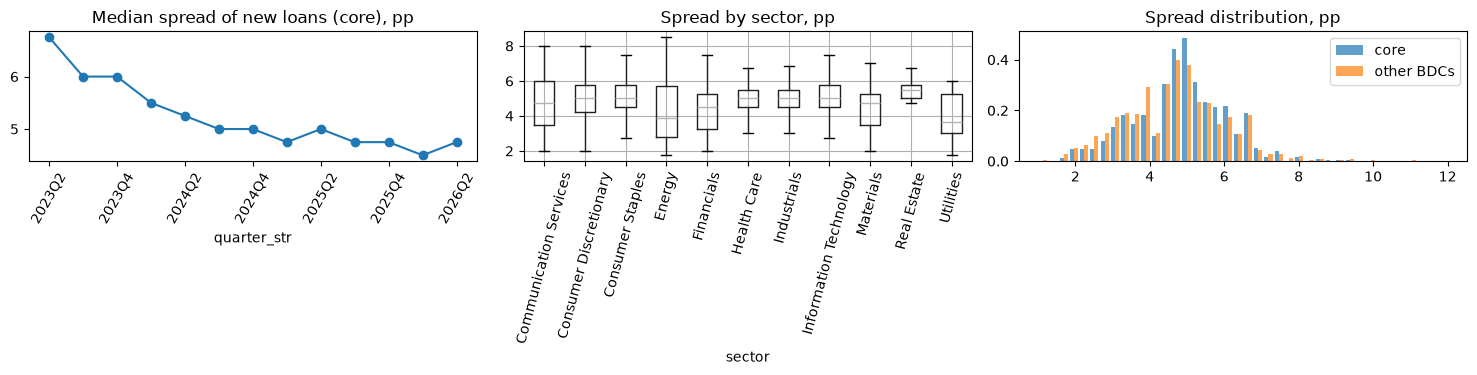

In [18]:
core_out["year"] = core_out.quarter_str.str[:4]
print(core_out.groupby("year").spread_pp.describe()[["count", "25%", "50%", "75%"]].round(2).to_string())
print(core_out.groupby("sector").spread_pp.describe()[["count", "25%", "50%", "75%"]].round(2)
      .sort_values("count", ascending=False).to_string())
print(core_out.groupby("family").spread_pp.describe()[["count", "50%"]].round(2)
      .sort_values("count", ascending=False).head(15).to_string())
print("lien:", core_out.lien.value_counts().to_dict(), " instrument:", core_out.instrument.value_counts().to_dict())
print("loans per quarter:", core_out.groupby("quarter_str").size().to_dict())

other = all_out[~all_out.industry_reporting_bdc]
comp = pd.DataFrame({
    "core (industry-reporting BDCs)": core_out[["spread_pp", "principal_family", "tenor_years"]].median(),
    "other BDCs": other[["spread_pp", "principal_family", "tenor_years"]].median()}).T
comp["n_loans"] = [len(core_out), len(other)]
comp["tenor_known_share"] = [1.0, other.tenor_years.notna().mean()]
print(comp.round(2).to_string())
comp.to_csv(TAB / "core_vs_other_bdcs.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
core_out.groupby("quarter_str").spread_pp.median().plot(ax=axes[0], marker="o")
axes[0].set_title("Median spread of new loans (core), pp")
axes[0].tick_params(axis="x", rotation=60)
core_out.boxplot(column="spread_pp", by="sector", ax=axes[1], rot=75, showfliers=False)
axes[1].set_title("Spread by sector, pp")
axes[2].hist([core_out.spread_pp, other.spread_pp], bins=40, range=(1, 12), density=True,
             label=["core", "other BDCs"], alpha=0.7)
axes[2].legend()
axes[2].set_title("Spread distribution, pp")
plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG / "spread_overview.png", dpi=120)
plt.show()

### 15d. Cutoff check of every feature

For each feature we state on which date its value is fixed and check it against the cutoff (start of the quarter).

In [19]:
cut = core_out.copy()
qs = pd.to_datetime(cut.quarter_start_date)
fred_dates = mkt[["baa_spread_prev_date", "sofr_prev_date"]]
checks = pd.DataFrame([
    ("tenor_years", "computed from quarter_start (contract term)", True),
    ("log_principal", "held principal at the reporting date (approximation of the planned hold)", True),
    ("sector, lien, instrument, family", "contract characteristics, fixed when the deal is signed", True),
    ("baa_spread_prev, sofr_prev", "FRED value dated before quarter_start",
     bool((fred_dates.lt(fred_dates.index.to_series(), axis=0)).all().all())),
    ("mkt_spread_t2_all", "loans of quarter t-2 filed before quarter_start", int(mkt.mkt_late_t2_all.sum()) >= 0),
], columns=["feature", "value fixed by", "check passed"])
print(checks.to_string(index=False))
# t-2 market spread: recompute for one quarter by hand and compare
q_test = pd.Period("2025Q1")
ref = market_pool[(market_pool.quarter == q_test - 2) & (market_pool.filed < q_test.start_time)]
assert np.isclose(ref.spread_pp.median(), mkt.loc[q_test.start_time, "mkt_spread_t2_all"])
assert checks["check passed"].all()

                         feature                                                           value fixed by  check passed
                     tenor_years                              computed from quarter_start (contract term)          True
                   log_principal held principal at the reporting date (approximation of the planned hold)          True
sector, lien, instrument, family                  contract characteristics, fixed when the deal is signed          True
      baa_spread_prev, sofr_prev                                    FRED value dated before quarter_start          True
               mkt_spread_t2_all                          loans of quarter t-2 filed before quarter_start          True


### 15e. Hand check against the original filings (50 loans, stratified by manager)

**Sample.** 50 loans drawn with seed 42 by the code below, proportionally to each family's share of the core
sample (at least one loan per family with 10 or more loans). The sample was drawn from the dataset **before** the
existing-loan filter of step 11 was added; that filter was a consequence of this hand check. The results are
therefore reported for all 50 loans and for the loans that remain in the final dataset.

**Procedure.** Each loan was looked up in its 10-Q/10-K on EDGAR (`inlineurl`): the borrower must be found, and
spread, maturity, principal and industry must match the schedule of investments. Each loan is classified as
(a) originated in that quarter, (b) originated earlier and acquired, (c) transferred from an affiliated vehicle,
using public evidence: acquisition or origination dates in the filing, earlier holdings of the same borrower at
other BDCs and their maturity dates (same maturity = the same loan already existed; earlier maturity = the new loan
is a refinancing), the remaining tenor (a fresh direct-lending loan has 5 to 7 years), and the age of the fund.
The evidence for every loan is in `docs/hand_check.csv` (column `evidence`, with a confidence level).

In [20]:
HC = ROOT / "docs" / "hand_check.csv"
if not HC.exists():          # draws the sample; the checked results are then entered into the file
    big = core_out.family.value_counts()
    big = big[big >= 10]
    alloc = np.maximum(np.floor(big / big.sum() * 50), 1).astype(int)
    rest = (big / big.sum() * 50 - np.floor(big / big.sum() * 50)).sort_values(ascending=False)
    for f in rest.index:
        if alloc.sum() >= 50:
            break
        alloc[f] += 1
    while alloc.sum() > 50:
        alloc[alloc.idxmax()] -= 1
    hc = pd.concat([core_out[core_out.family == f].sample(n, random_state=SEED) for f, n in alloc.items()])
    hc = hc[["loan_id", "family", "bdc_name", "quarter_str", "borrower", "spread_pp", "maturity_date",
             "principal", "industry", "inlineurl"]].copy()
    for c in ["found_in_filing", "spread_ok", "maturity_ok", "principal_ok", "industry_ok", "class_abc",
              "confidence", "evidence"]:
        hc[c] = ""
    hc.to_csv(HC, index=False)
hc = pd.read_csv(HC, dtype={"loan_id": str})
# A checked loan is in the final sample when loans.csv has a loan of the same quarter and manager family (family
# from the BDC name with the current rules) with the same maturity (within 7 days) or the same spread, sharing a
# distinctive word of the borrower name (legal and generic words such as "Inc", "Holdings" do not count). This does
# not depend on the loan_id (a hash that changes when a family is re-mapped) or on the spelling of the parsed name.
def name_words(b):
    t = [x for x in up.tokens(b) if x not in up.LEGAL_WORDS]
    return {x for x in t if len(x) >= 3 and x not in up.GENERIC_NAME_WORDS} or set(t)


def find_in_final(r):
    c = core_out[(core_out.quarter_str == r.quarter_str) & (core_out.family == up.family_of_names([r.bdc_name]))]
    same_terms = ((pd.to_datetime(c.maturity_date) - pd.Timestamp(r.maturity_date)).abs().dt.days <= 7)         | np.isclose(c.spread_pp, r.spread_pp)
    c = c[same_terms]
    words = name_words(r.borrower)
    c = c[[bool(words & name_words(b)) for b in c.borrower]] if len(c) else c
    return c.loan_id.iloc[0] if len(c) else None


hc["loan_id_now"] = [find_in_final(r) for r in hc.itertuples()]
hc["in_final_sample"] = hc.loan_id_now.notna()
print("checked loans whose loan_id changed since the check (family re-mapping):",
      int((hc.in_final_sample & (hc.loan_id_now != hc.loan_id)).sum()))
print("hand-checked loans:", len(hc), " families:", hc.family.nunique(),
      " still in the final sample:", int(hc.in_final_sample.sum()))
for c in ["found_in_filing", "spread_ok", "maturity_ok", "principal_ok", "industry_ok"]:
    print(f"{c:16s} matches: {hc[c].astype(str).str.startswith('yes').sum()} of {len(hc)}"
          f" (others: value tagged in XBRL but not printed next to the name)")


def class_shares(d, label):
    rows = []
    for k in ["a", "b", "c"]:
        n_k = int((d.class_abc == k).sum())
        lo, hi = up.wilson_ci(n_k, len(d))
        rows.append({"sample": label, "class": k, "n": n_k, "share": n_k / len(d), "ci_low": lo, "ci_high": hi})
    return rows


shares = pd.DataFrame(class_shares(hc, f"all checked ({len(hc)})")
                      + class_shares(hc[hc.in_final_sample], f"in final sample ({int(hc.in_final_sample.sum())})"))
shares.to_csv(TAB / "hand_check_shares.csv", index=False)
print(shares.round(3).to_string(index=False))
print("removed by the existing-loan / all-in-rate filters, by class:",
      hc[~hc.in_final_sample].class_abc.value_counts().to_dict())
share_a_final = shares.query("`class` == 'a' and sample.str.startswith('in final')", engine="python").share.iloc[0]
print("Commitment: target stays 'spread of newly originated loans' if share (a) >= 0.80 ->",
      "kept" if share_a_final >= 0.8 else "reinterpret as 'spread of loans newly added to a BDC portfolio'")

checked loans whose loan_id changed since the check (family re-mapping): 5
hand-checked loans: 50  families: 29  still in the final sample: 39
found_in_filing  matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
spread_ok        matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
maturity_ok      matches: 49 of 50 (others: value tagged in XBRL but not printed next to the name)
principal_ok     matches: 50 of 50 (others: value tagged in XBRL but not printed next to the name)
industry_ok      matches: 48 of 50 (others: value tagged in XBRL but not printed next to the name)
              sample class  n  share  ci_low  ci_high
    all checked (50)     a 35  0.700   0.562    0.809
    all checked (50)     b 14  0.280   0.175    0.417
    all checked (50)     c  1  0.020   0.004    0.105
in final sample (39)     a 33  0.846   0.703    0.928
in final sample (39)     b  5  0.128   0.056    0.267
in final sample (39)     c  1  0.026  